# Drug overdose deaths and suicides in the United States, 2001–2021

Is there a relationship between drug overdose deaths and suicides in the US?
We compare both rates year by year and look at how each one grew.

**Inputs**
- `data/processed/usa_suicide_rate.csv`: suicide deaths by state and year (CDC; created from the raw CDC file with `src/compute_suicide_rates.py`).
- `data/processed/usa_population.csv`: population by state and year (U.S. Census Bureau).
- `data/processed/drug_overdose_us_2001_2021.csv`: drug overdose deaths per year (NCHS Data Brief 457, extracted with `src/extract_overdose_pdf.py`).
- `data/processed/usa_real_gdp.csv`: real GDP by state and year (BEA via FRED; created with `src/download_economic_data.py`). The national GDP is the sum of the states.
- The *Pulling Data* cell also loads the yearly weather tables and the Spanish suicide data, which are not used in this notebook.

**Outputs.** None: the table and the figure are shown in the notebook.

**Method.** Both rates are crude rates per 100,000 inhabitants. We fit a straight line to the logarithms of both rates (a power law) and show ±1 and ±2 standard deviations of the residuals around it. Because both rates grow over time, the correlation of the yearly levels is much higher than the correlation of their year-to-year changes.

**How to run.** Open the notebook from the `notebooks/` folder and use *Run All*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter

In [2]:
from pathlib import Path

# Repository root: the first folder, going up from this notebook, that contains "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw"              # original downloads (not uploaded to GitHub)
INTERIM = ROOT / "data" / "interim"      # large intermediate files (not uploaded to GitHub)
PROCESSED = ROOT / "data" / "processed"  # clean tables used in the analysis

## Pulling Data

In [4]:
WeatherNL = pd.read_csv(PROCESSED / 'NL_yearly.csv')
WeatherUSA = pd.read_csv(PROCESSED / 'usa_yearly.csv')
WeatherESP = pd.read_csv(PROCESSED / 'spain_yearly.csv')
DEsp = pd.read_csv(PROCESSED / 'spain_suicide_rate.csv')     # suicide deaths by Spanish region and year (INE)
DUSA = pd.read_csv(PROCESSED / 'usa_suicide_rate.csv')       # suicide deaths by state and year (CDC)

# Used in this notebook
PopUSA = pd.read_csv(PROCESSED / 'usa_population.csv')                  # population by state and year (U.S. Census Bureau)
OverdoseUSA = pd.read_csv(PROCESSED / 'drug_overdose_us_2001_2021.csv')  # overdose deaths per year (NCHS Data Brief 457)
GdpUSA = pd.read_csv(PROCESSED / 'usa_real_gdp.csv')                    # real GDP by state and year (BEA via FRED)

## Rates per 100,000 inhabitants

Overdoses come for the whole country, so we add up the suicides and the population of all states for each year.

In [5]:
# Total suicides and population of the US for each year
suicides = DUSA.groupby("Year")["Deaths"].sum().rename("suicides")
population = PopUSA.groupby("year")["population"].sum()

# One table with one row per year
d = OverdoseUSA.set_index("year").join(suicides).join(population)

# Deaths per 100,000 inhabitants
d["overdose_per_100k"] = d["deaths_total"] / d["population"] * 100000
d["suicides_per_100k"] = d["suicides"] / d["population"] * 100000

# Real GDP of the US: sum of the 50 states and DC, in trillions of 2017 dollars
d["real_gdp_trillions"] = GdpUSA.groupby("year")["real_gdp_millions"].sum() / 1e6

d[["deaths_total", "suicides", "population", "overdose_per_100k", "suicides_per_100k"]]

,deaths_total,suicides,population,overdose_per_100k,suicides_per_100k
year,,,,,
2001,19394,30622,284968955,6.805654,10.745732
2002,23518,31655,287625193,8.176613,11.005642
2003,25785,31484,290107933,8.888071,10.852513
2004,27424,32439,292805298,9.365951,11.078693
2005,29813,32637,295516599,10.088435,11.044050
2006,34425,33300,298379912,11.537305,11.160269
2007,36010,34598,301231207,11.954273,11.485530
2008,36450,36035,304093966,11.986427,11.849956
2009,37004,36909,306771529,12.062397,12.031429


## Fit in log–log

We fit a straight line to the logarithms of both rates (a power law).
The slope says how much suicides grow when overdoses grow, and the standard deviation of the residuals says how far the years are from the line.

In [6]:
lx = np.log10(d["overdose_per_100k"])
ly = np.log10(d["suicides_per_100k"])

slope, intercept = np.polyfit(lx, ly, 1)               # straight line in log-log
r = np.corrcoef(lx, ly)[0, 1]                           # correlation
std = np.std(ly - (intercept + slope * lx), ddof=2)     # spread of the points around the line

print(f"Slope = {slope:.2f}   R² = {r**2:.2f}   std of residuals = {std:.3f}")

Slope = 0.25   R² = 0.85   std of residuals = 0.019


## Plots

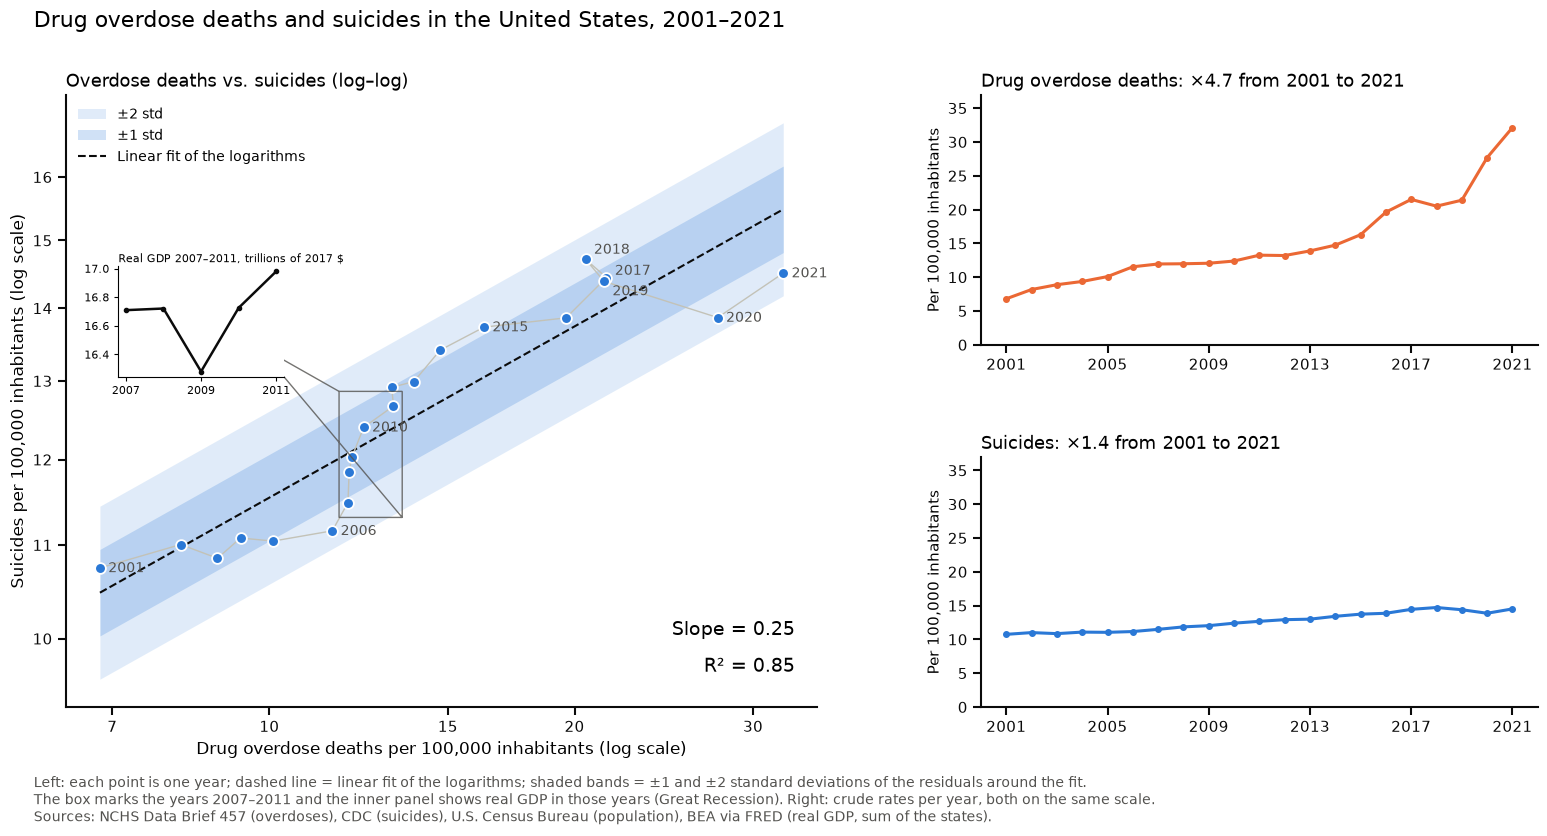

In [7]:
BLUE, ORANGE, INK, INK2 = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

def style(ax):
    # Visible axes and no grid
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK)
        ax.spines[side].set_linewidth(1.5)
    ax.tick_params(colors=INK, width=1.5, length=6, labelsize=11)

fig = plt.figure(figsize=(16, 8.5))
grid = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.45, wspace=0.25)
ax = fig.add_subplot(grid[:, 0])      # left: overdoses vs suicides
ax_od = fig.add_subplot(grid[0, 1])   # top right: overdoses over time
ax_su = fig.add_subplot(grid[1, 1])   # bottom right: suicides over time

# Left plot: log-log scale
ax.set_xscale("log")
ax.set_yscale("log")

# Fitted line with faded bands of ±1 and ±2 standard deviations
x = np.logspace(lx.min(), lx.max(), 100)
y = intercept + slope * np.log10(x)
for k, alpha in [(2, 0.14), (1, 0.22)]:
    ax.fill_between(x, 10 ** (y - k * std), 10 ** (y + k * std), color=BLUE, alpha=alpha, lw=0, label=f"±{k} std", zorder=1)
ax.plot(x, 10 ** y, color=INK, lw=1.5, ls="--", zorder=2, label="Linear fit of the logarithms")

# One point per year, joined in order
ax.plot(d["overdose_per_100k"], d["suicides_per_100k"], color="#c3c2b7", lw=1, zorder=3)
ax.scatter(d["overdose_per_100k"], d["suicides_per_100k"], s=60, color=BLUE, edgecolor="white", lw=1.3, zorder=4)
offsets = {2017: (6, 2), 2018: (6, 4), 2019: (6, -10)}
for year in [2001, 2006, 2010, 2015, 2017, 2018, 2019, 2020, 2021]:
    ax.annotate(str(year), (d.loc[year, "overdose_per_100k"], d.loc[year, "suicides_per_100k"]),
                xytext=offsets.get(year, (6, -3)), textcoords="offset points", fontsize=10, color=INK2, zorder=5)

# Plain numbers on the log axes
ax.xaxis.set_major_locator(FixedLocator([7, 10, 15, 20, 30]))
ax.yaxis.set_major_locator(FixedLocator([10, 11, 12, 13, 14, 15, 16]))
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(ScalarFormatter())
    axis.set_minor_locator(NullLocator())

style(ax)
ax.set_xlabel("Drug overdose deaths per 100,000 inhabitants (log scale)", fontsize=12)
ax.set_ylabel("Suicides per 100,000 inhabitants (log scale)", fontsize=12)
ax.text(0.97, 0.11, f"Slope = {slope:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=14)
ax.text(0.97, 0.05, f"R² = {r**2:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=14)
ax.legend(loc="upper left", frameon=False, fontsize=10)
ax.set_title("Overdose deaths vs. suicides (log–log)", fontsize=13, loc="left")

# Inner panel with the real GDP of 2007-2011 (the Great Recession), linked to a box around those years
crisis = d.loc[2007:2011]
inset = ax.inset_axes([0.07, 0.54, 0.22, 0.18])   # [left, bottom, width, height] as fractions of the plot
inset.plot(crisis.index, crisis["real_gdp_trillions"], color=INK, lw=1.8, marker="o", ms=3)
inset.set_xticks([2007, 2009, 2011])
inset.tick_params(labelsize=8, length=3)
inset.set_title("Real GDP 2007–2011, trillions of 2017 $", fontsize=8, loc="left", pad=3)
for side in ("top", "right"):
    inset.spines[side].set_visible(False)
x0, x1 = crisis["overdose_per_100k"].min() * 0.98, crisis["overdose_per_100k"].max() * 1.02
y0, y1 = crisis["suicides_per_100k"].min() * 0.985, crisis["suicides_per_100k"].max() * 1.015
ax.indicate_inset([x0, y0, x1 - x0, y1 - y0], inset_ax=inset, edgecolor=INK2, alpha=0.8, lw=1)

# Right plots: growth of each rate over time, both on the same y scale
ymax = max(d["overdose_per_100k"].max(), d["suicides_per_100k"].max()) * 1.15
for a, col, color, title in [(ax_od, "overdose_per_100k", ORANGE, "Drug overdose deaths"),
                             (ax_su, "suicides_per_100k", BLUE, "Suicides")]:
    a.plot(d.index, d[col], color=color, lw=2.2, marker="o", ms=4)
    a.set_ylim(0, ymax)
    a.set_xticks(range(2001, 2022, 4))
    style(a)
    growth = d[col].iloc[-1] / d[col].iloc[0]          # how many times it grew from 2001 to 2021
    a.set_title(f"{title}: ×{growth:.1f} from 2001 to 2021", fontsize=13, loc="left")
    a.set_ylabel("Per 100,000 inhabitants", fontsize=11)

fig.suptitle("Drug overdose deaths and suicides in the United States, 2001–2021", fontsize=16, x=0.04, ha="left")

# Caption below the plots
fig.text(0.04, 0.02,
         "Left: each point is one year; dashed line = linear fit of the logarithms; shaded bands = ±1 and ±2 standard deviations of the residuals around the fit.\n"
         "The box marks the years 2007–2011 and the inner panel shows real GDP in those years (Great Recession). Right: crude rates per year, both on the same scale.\n"
         "Sources: NCHS Data Brief 457 (overdoses), CDC (suicides), U.S. Census Bureau (population), BEA via FRED (real GDP, sum of the states).",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.88, left=0.06, right=0.98, bottom=0.16)
plt.show()

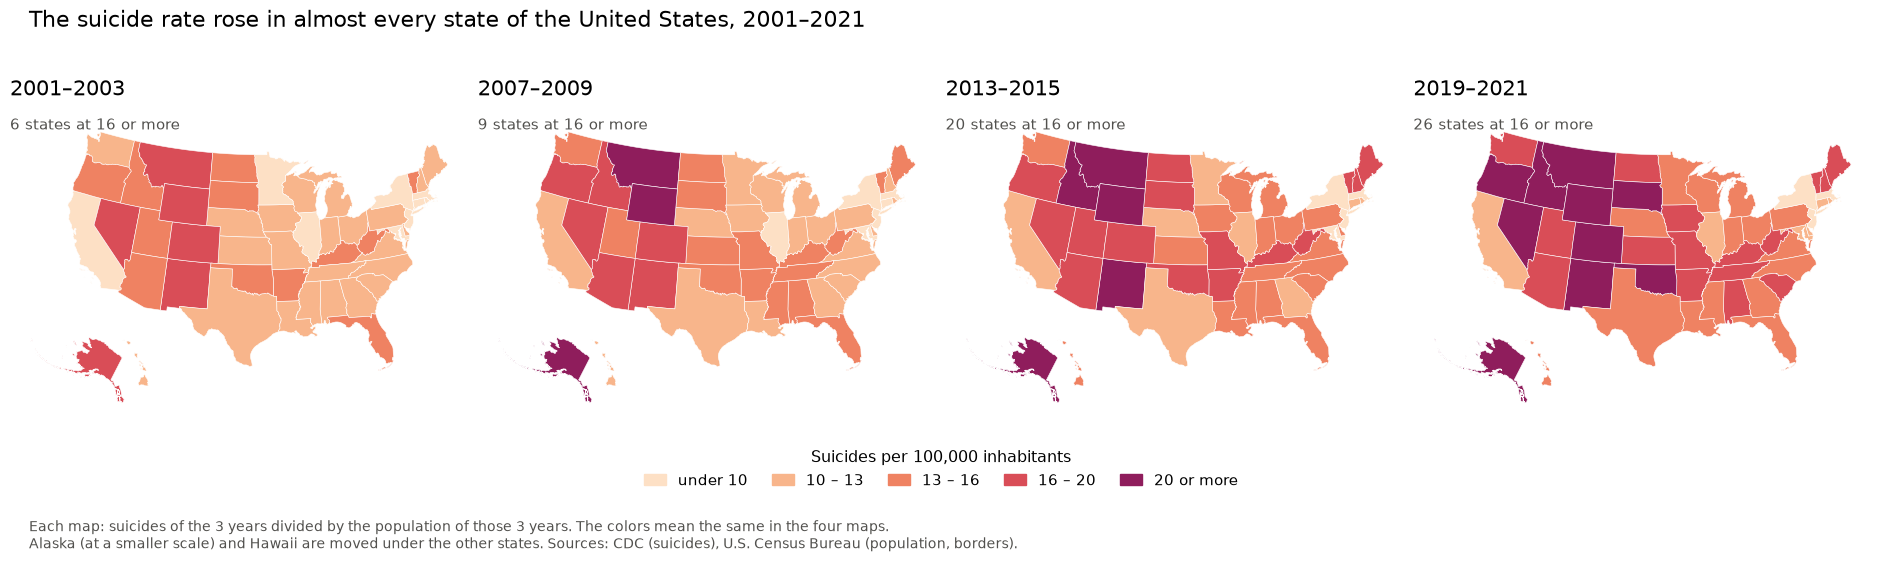

In [8]:
import geopandas as gpd
from shapely import affinity
from matplotlib.patches import Patch

PERIODS = [(2001, 2003), (2007, 2009), (2013, 2015), (2019, 2021)]   # one map per period (mean of 3 years)
LIMITS = [0, 10, 13, 16, 20, 100]                                    # classes of the suicide rate, per 100,000 inhabitants
COLORS = ["#fde0c5", "#f8b58b", "#ef8262", "#d94d57", "#8f1d5c"]     # light = low, dark = high
INK, INK2 = "#0b0b0b", "#52514e"

# Suicide rate of each state in each period (suicides and population already in data/processed)
sui = DUSA.rename(columns={"Year": "year", "Location": "region_name", "Deaths": "suicides"})
t = PopUSA.merge(sui[["region_name", "year", "suicides"]], on=["region_name", "year"])
rates = {}
for first, last in PERIODS:
    p = t[t["year"].between(first, last)].groupby("region_name")[["population", "suicides"]].sum()
    rates[(first, last)] = p["suicides"] / p["population"] * 100000

# State borders (U.S. Census Bureau); Alaska and Hawaii are moved under the other 48
states = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_20m.zip")
states = states[states["STATEFP"].astype(int) <= 56].to_crs("EPSG:5070")
def move(code, scale, dx, dy):
    i = states["STUSPS"] == code
    states.loc[i, "geometry"] = states.loc[i, "geometry"].apply(
        lambda g: affinity.translate(affinity.scale(g, scale, scale, origin=(0, 0)), dx, dy))
move("AK", 0.35, -0.9e6, -1.5e6)
move("HI", 1.0, 4.6e6, -1.45e6)

fig, axes = plt.subplots(1, len(PERIODS), figsize=(19, 5.6), gridspec_kw={"wspace": 0.02})
for ax, period in zip(axes, PERIODS):
    rate = states["NAME"].map(rates[period])
    classes = pd.cut(rate, LIMITS, labels=False, right=False)
    states.plot(ax=ax, color=[COLORS[int(c)] for c in classes], edgecolor="white", linewidth=0.4)
    ax.set_axis_off()
    ax.set_title(f"{period[0]}–{period[1]}", fontsize=15, loc="left")
    ax.text(0.0, 1.0, f"{(rate >= 16).sum()} states at 16 or more", transform=ax.transAxes, fontsize=10.5, color=INK2, va="top")

# One legend for the four maps
labels = ["under 10", "10 – 13", "13 – 16", "16 – 20", "20 or more"]
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(COLORS, labels)], title="Suicides per 100,000 inhabitants",
           loc="lower center", bbox_to_anchor=(0.5, 0.1), ncol=5, frameon=False, fontsize=11, title_fontsize=11.5,
           columnspacing=1.6, handlelength=1.4)
fig.suptitle("The suicide rate rose in almost every state of the United States, 2001–2021", fontsize=16, x=0.02, ha="left")

# Caption below the maps
fig.text(0.02, 0.01,
         "Each map: suicides of the 3 years divided by the population of those 3 years. The colors mean the same in the four maps.\n"
         "Alaska (at a smaller scale) and Hawaii are moved under the other states. Sources: CDC (suicides), U.S. Census Bureau (population, borders).",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.84, left=0.01, right=0.99, bottom=0.2)
plt.show()